# Taller 2 — PPO (Hugo)

**Grupo:** Javier Chulvi Bernad · Hugo Vinuesa Busson · Higinio Paterna Ortiz

Javi implementó **DQN** y Higinio **A3C**. Este notebook añade un tercer algoritmo, **PPO** (*Proximal Policy Optimization*),
y lo evalúa bajo exactamente el mismo protocolo para que los tres sean comparables:

- mismo entorno, generadores y **estado** (tendencia de 6 precios y posición), con una única diferencia de preprocesado documentada en §2: la tendencia se **estandariza** por mercado antes de entrar en la red;
- misma red: tronco 2-32-32 con tanh, cabeza actor (3 logits) y cabeza crítico V(s), misma inicialización que A3C;
- mismo presupuesto: **1.000 episodios × 500 precios** por modelo, **5 semillas (101, 202, 303, 404, 505)** y las mismas series de entrenamiento (`SeedSequence([semilla, mercado, episodio, 0])`);
- mismos bancos: **50 series de validación** (semilla 5.000) para elegir hiperparámetros y **200 series de test** (semilla 10.000) para una única evaluación final, con huellas SHA-256 verificadas;
- mismas métricas acordadas: retorno medio, desviación entre semillas, percentil 5, operaciones y tiempo de entrenamiento;
- mismo criterio de selección que DQN: retorno medio en validación, desempate por P05 y menor dispersión entre semillas.

**Por qué PPO.** A3C y PPO son actor-crítico con gradiente de política; la diferencia es cómo se actualiza la política. A3C da un paso de
gradiente por rollout y descarta los datos. PPO reutiliza cada lote durante varias épocas y limita el cambio de la política con un objetivo
*recortado*: si la probabilidad de una acción cambia más de un factor 1 ± ε respecto a la política que generó los datos, la ventaja deja de
empujar. Esto permite aprender más de cada transición sin que la política se desestabilice, y en la práctica es el algoritmo más usado hoy
en RL profundo. Frente a DQN, aprende directamente una política estocástica en vez de valores Q, no necesita *replay* ni red objetivo.

**Más allá del mínimo.** Como en la parte 1, se prueba además PPO con el **estado enriquecido** (distancia del precio a su media de 20 pasos),
con la misma configuración elegida y sin reajustar, y se compara serie a serie sobre el test común.

## 1. Entorno, generadores y protocolo común

In [1]:
from dataclasses import dataclass, asdict
from time import perf_counter
from copy import deepcopy
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
from torch import nn
from torch.distributions import Categorical
from scipy.stats import wilcoxon
from IPython.display import Markdown, display

torch.set_num_threads(1)

# ----------------------------------------------------------------------------- entorno (copiado del enunciado)
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1
        self.action_space = spaces.Discrete(3)
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32), dtype=np.float32)

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5
        self.position = 0
        self.initial_balance = 1000.0
        self.balance = self.initial_balance
        self.cash = self.initial_balance
        self.shares = 0.0
        return self._get_obs(), {}

    def _get_obs(self):
        window = self.prices[self.current_step - 5: self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]
        reward = 0.0
        cost_rate = 0.001
        if action == 2 and self.position == 0:
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate
        elif action == 0 and self.position == 1:
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash
        terminated = self.current_step >= self.max_steps
        return self._get_obs(), reward, terminated, False, {"balance": self.balance}

In [2]:
def _resolver_rng(rng):
    if rng is None:
        return np.random.default_rng()
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng debe ser una instancia de np.random.Generator")
    return rng


def generar_precios(n_steps=1000, rng=None):
    rng = _resolver_rng(rng)
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = rng.normal(0, 0.1, n_steps)
    retornos = drift + ciclo + ruido
    return 100 * np.cumprod(1 + retornos)


def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02, rng=None):
    rng = _resolver_rng(rng)
    dt = 1.0
    retornos = rng.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    return start_price * np.cumprod(np.exp(retornos))


def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02, rng=None):
    rng = _resolver_rng(rng)
    precios = np.zeros(n_steps)
    precios[0] = start_price
    for t in range(1, n_steps):
        delta = kappa * (mean_price - precios[t-1]) + rng.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta
        precios[t] = max(precios[t], 0.1)
    return precios


def generar_precios_regimenes(n_steps=1000, start_price=100.0, rng=None):
    rng = _resolver_rng(rng)
    precios = np.zeros(n_steps)
    precios[0] = start_price
    estado = 0
    retornos = []
    for _ in range(n_steps):
        if rng.random() < 0.02:
            estado = 1 - estado
        if estado == 0:
            ret = rng.normal(0.001, 0.01)
        else:
            ret = rng.normal(-0.0015, 0.025)
        retornos.append(ret)
    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)
    return np.maximum(precios, 0.1)

### Protocolo común de reproducibilidad

Para que los resultados de distintos notebooks sean comparables, todos deben reutilizar *los mismos bancos de series*, sin regenerarlos a partir del estado global de NumPy. Se fija el siguiente protocolo:

| Partición | Series por generador | Precios por serie | Semilla de precios | Semilla de acciones | Uso |
|:--|--:|--:|--:|--:|:--|
| Validación | 50 | 500 | 5.000 | 6.000 | Selección de hiperparámetros |
| Test final | 200 | 500 | 10.000 | 20.000 | Una única evaluación final |

Las semillas de entrenamiento comunes son (101, 202, 303, 404, 505). Cada combinación (partición, generador, número de serie) crea un `Generator` independiente mediante `SeedSequence`; por ello, ejecutar otras celdas o cambiar su orden no altera los bancos. Las huellas SHA-256 del test se comprueban contra las de Higinio y Javi.

In [3]:
@dataclass(frozen=True)
class EvaluationProtocol:
    """Define un banco de evaluación reproducible e independiente."""

    name: str
    n_series: int
    n_steps: int
    price_seed: int
    action_seed: int

    def __post_init__(self):
        if not self.name:
            raise ValueError("name no puede estar vacío")
        if self.n_series <= 0:
            raise ValueError("n_series debe ser positivo")
        if self.n_steps < 7:
            raise ValueError("n_steps debe ser al menos 7")
        if self.price_seed < 0 or self.action_seed < 0:
            raise ValueError("las semillas no pueden ser negativas")

    @staticmethod
    def _rng(base_seed, generator_id, series_index):
        if generator_id < 0 or series_index < 0:
            raise ValueError("generator_id y series_index no pueden ser negativos")
        seed_sequence = np.random.SeedSequence([base_seed, generator_id, series_index])
        return np.random.default_rng(seed_sequence)

    def price_rng(self, generator_id, series_index):
        return self._rng(self.price_seed, generator_id, series_index)

    def action_rng(self, generator_id, series_index):
        return self._rng(self.action_seed, generator_id, series_index)

    def generate_dataset(self, price_generator, generator_id):
        series = [np.asarray(price_generator(n_steps=self.n_steps, rng=self.price_rng(generator_id, series_index)),
                             dtype=np.float64) for series_index in range(self.n_series)]
        dataset = np.stack(series)
        if dataset.shape != (self.n_series, self.n_steps):
            raise ValueError("el generador devolvió una forma no válida")
        if not np.all(np.isfinite(dataset)) or np.any(dataset <= 0.0):
            raise ValueError("los precios deben ser finitos y positivos")
        return dataset


TRAINING_SEEDS = (101, 202, 303, 404, 505)
VALIDATION_PROTOCOL = EvaluationProtocol(name="validation", n_series=50, n_steps=500, price_seed=5_000, action_seed=6_000)
TEST_PROTOCOL = EvaluationProtocol(name="test", n_series=200, n_steps=500, price_seed=10_000, action_seed=20_000)

PRICE_GENERATORS = {
    "tendencia_ciclo": (0, generar_precios),
    "browniano": (1, generar_precios_browniano),
    "reversion_media": (2, generar_precios_reversion_media),
    "regimenes": (3, generar_precios_regimenes),
}
MARKET_LABELS = {"tendencia_ciclo": "Tendencia + ciclo", "browniano": "Browniano",
                 "reversion_media": "Reversión a la media", "regimenes": "Cambios de régimen"}


def generate_evaluation_datasets(protocol):
    return {name: protocol.generate_dataset(generator, generator_id)
            for name, (generator_id, generator) in PRICE_GENERATORS.items()}


def dataset_fingerprint(dataset):
    normalized = np.ascontiguousarray(dataset, dtype="<f8")
    return hashlib.sha256(normalized.tobytes()).hexdigest()


EXPECTED_TEST_FINGERPRINTS = {
    'tendencia_ciclo': 'f7ba229a24755ad123d0b01e608ed72e16f347bb16be7c87fd309e1afb38763d',
    'browniano': 'd05b4102b634985e678b6a0511fcd0497d524f3b4b72d396043ebe25e362688d',
    'reversion_media': '16ac74754351e609c738490d97f7c69383a10a31c4920d4b25423df215d86339',
    'regimenes': '061f1f1ef1f21f034eea600b65d5d87702d4430699cf38250fb552fb58b013ce'}

VALIDATION_DATASETS = generate_evaluation_datasets(VALIDATION_PROTOCOL)
TEST_DATASETS = generate_evaluation_datasets(TEST_PROTOCOL)
FINGERPRINT_MATCHES = {k: dataset_fingerprint(v) == EXPECTED_TEST_FINGERPRINTS[k] for k, v in TEST_DATASETS.items()}
import platform
print(f"Plataforma: {platform.system()} {platform.machine()}, NumPy {np.__version__}")
print("Huella SHA-256 del test idéntica a la de Higinio/Javi:", FINGERPRINT_MATCHES)
if not all(FINGERPRINT_MATCHES.values()):
    print("AVISO: las huellas de Higinio y Javi se generaron en macOS/ARM. En otras plataformas (este caso) tres de los cuatro")
    print("generadores difieren en el ULTIMO BIT (FMA en media + desv*z, y sin/exp vectorizados): diferencia relativa maxima ~4e-15.")
    print("Las series son las mismas a efectos practicos; en la seccion 6 se comprueba que los baselines sobre este banco coinciden")
    print("exactamente con los del informe DQN/A3C (buy & hold 42.092,90 % / 9,08 % / -0,30 % / -9,21 %).")

Plataforma: Linux x86_64, NumPy 2.5.3
Huella SHA-256 del test idéntica a la de Higinio/Javi: {'tendencia_ciclo': False, 'browniano': False, 'reversion_media': True, 'regimenes': False}
AVISO: las huellas de Higinio y Javi se generaron en macOS/ARM. En otras plataformas (este caso) tres de los cuatro
generadores difieren en el ULTIMO BIT (FMA en media + desv*z, y sin/exp vectorizados): diferencia relativa maxima ~4e-15.
Las series son las mismas a efectos practicos; en la seccion 6 se comprueba que los baselines sobre este banco coinciden
exactamente con los del informe DQN/A3C (buy & hold 42.092,90 % / 9,08 % / -0,30 % / -9,21 %).


> **Nota de reproducibilidad (análisis crítico).** Regenerar los bancos con `SeedSequence` garantiza las mismas series solo si el
> hardware y las librerías redondean igual. Al ejecutar este notebook en Linux x86 las huellas SHA-256 de tendencia, browniano y
> regímenes no coinciden con las de macOS/ARM aunque el código sea idéntico: en ARM el compilador fusiona `media + desviación·z`
> en una operación FMA (emulándolo con `math.fma` se reproduce exactamente la huella de regímenes) y las versiones vectorizadas de
> `sin`/`exp` difieren por arquitectura. La diferencia relativa es ≤ 4·10⁻¹⁵ y no altera ningún resultado (los baselines salen idénticos
> al informe), pero para una reproducibilidad estricta convendría versionar los bancos como fichero `.npz` en lugar de regenerarlos.

In [4]:
def training_prices(generator_name, training_seed, episode_index, n_steps=500):
    """Misma serie de entrenamiento que usan A3C y DQN para (semilla, mercado, episodio)."""
    generator_id, generator = PRICE_GENERATORS[generator_name]
    rng = np.random.default_rng(np.random.SeedSequence([training_seed, generator_id, episode_index, 0]))
    return np.asarray(generator(n_steps=n_steps, rng=rng), dtype=np.float64)

## 2. Estados, estandarización y entorno vectorizado

**Estandarización de la observación (decisión de diseño).** La tendencia del enunciado vale típicamente ±0,02 (±0,15 en el mercado de
tendencia) mientras la posición vale 0 o 1. Con la red inicializada como en A3C, el gradiente respecto a los pesos de la tendencia es
unas 40 veces menor que respecto al sesgo: PPO aprende primero la *acción constante* (comprar siempre o no operar), reduce la entropía y
deja de explorar antes de llegar a usar la tendencia. En una primera búsqueda completa con la observación sin tratar, las 24 configuraciones
degeneraron en *buy & hold* o efectivo en los cuatro mercados (§5 bis reproduce el fenómeno en pequeño). DQN no lo sufre tanto porque
su ε-greedy fuerza exploración durante 150-300 k transiciones. La solución estándar en PPO es normalizar las observaciones: aquí cada
componente continua se divide por su desviación típica medida en **10 series de entrenamiento** (semilla 101, episodios 0-9); nunca
se usan validación ni test. La información del estado es exactamente la misma; solo cambia la escala de entrada a la red.

`VectorTradingEnv` ejecuta N copias de `SimpleTradingEnv` sobre N series a la vez con la **misma dinámica, comisiones y recompensa**
(comprobado bit a bit en la celda siguiente). El estado **original** es el del enunciado; el **enriquecido** añade la distancia del precio
a su media móvil de 20 pasos (solo precios ya observados), igual que en la parte 1.

In [5]:
def obs_raw(prices, t, position):
    """Observación del enunciado, vectorizada sobre series: (tendencia 6 precios, posición)."""
    window = prices[:, t - 5: t + 1]
    mean = window.mean(axis=1)
    trend = np.clip((window[:, -1] - mean) / mean, -1.0, 1.0)
    return np.stack([trend, position.astype(np.float64)], axis=1).astype(np.float32)


MA_WINDOW = 20


def dist_raw(prices, t):
    """Distancia del precio a su media móvil de 20 pasos (solo precios ya observados)."""
    w = prices[:, max(0, t - MA_WINDOW + 1): t + 1]
    return np.clip(prices[:, t] / w.mean(axis=1) - 1.0, -1.0, 1.0).astype(np.float32)


def observation_scales(generator_name, n_series=10, seed=101):
    """Estandarización de la observación: desviación típica de tendencia y distancia en 10 series de
    ENTRENAMIENTO (semilla 101, episodios 0-9). Nunca usa validación ni test. La posición (0/1) no se escala."""
    P = np.stack([training_prices(generator_name, seed, e) for e in range(n_series)])
    trend = np.concatenate([obs_raw(P, t, np.zeros(n_series))[:, 0] for t in range(5, P.shape[1] - 1)])
    dist = np.concatenate([dist_raw(P, t) for t in range(5, P.shape[1] - 1)])
    return {"trend": float(trend.std()), "dist": float(dist.std())}


OBS_SCALES = {name: observation_scales(name) for name in PRICE_GENERATORS}


def make_obs_fn(state, generator_name):
    """Devuelve la función de observación (vectorizada) del estado indicado, ya estandarizada para el mercado."""
    sc = OBS_SCALES[generator_name]
    if state == "original":
        return 2, lambda prices, t, position: obs_raw(prices, t, position) * np.array([1 / sc["trend"], 1.0], dtype=np.float32)
    if state == "enriquecido":
        def fn(prices, t, position):
            base = obs_raw(prices, t, position)
            return np.stack([base[:, 0] / sc["trend"], dist_raw(prices, t) / sc["dist"], base[:, 1]], axis=1).astype(np.float32)
        return 3, fn
    raise ValueError(state)


STATE_DIMS = {"original": 2, "enriquecido": 3}


class VectorTradingEnv:
    """N copias de SimpleTradingEnv en paralelo (misma dinámica, mismas comisiones, mismo reward)."""

    def __init__(self, prices, obs_fn=obs_raw):
        self.prices = np.asarray(prices, dtype=np.float64)
        self.n, self.T = self.prices.shape
        self.max_steps = self.T - 1
        self.obs_fn = obs_fn

    def reset(self):
        self.t = 5
        self.position = np.zeros(self.n, dtype=np.int64)
        self.cash = np.full(self.n, 1000.0)
        self.shares = np.zeros(self.n)
        self.balance = np.full(self.n, 1000.0)
        return self.obs_fn(self.prices, self.t, self.position)

    def step(self, action):
        prev = self.prices[:, self.t]
        self.t += 1
        curr = self.prices[:, self.t]
        reward = np.zeros(self.n)
        buy = (action == 2) & (self.position == 0)
        sell = (action == 0) & (self.position == 1)
        self.shares[buy] = (self.cash[buy] - self.cash[buy] * 0.001) / prev[buy]
        self.cash[buy] = 0.0
        self.position[buy] = 1
        reward[buy] -= 0.001
        sale = self.shares[sell] * prev[sell]
        self.cash[sell] = sale - sale * 0.001
        self.shares[sell] = 0.0
        self.position[sell] = 0
        reward[sell] -= 0.001
        held = self.position == 1
        reward[held] += (curr[held] - prev[held]) / prev[held]
        self.balance = np.where(held, self.cash + self.shares * curr, self.cash)
        done = self.t >= self.max_steps
        return self.obs_fn(self.prices, self.t, self.position), reward, done

In [6]:
# Comprobación: el entorno vectorizado reproduce exactamente SimpleTradingEnv
rng = np.random.default_rng(0)
for name in PRICE_GENERATORS:
    data = VALIDATION_DATASETS[name][:5]
    actions = rng.integers(3, size=(5, 494))
    venv = VectorTradingEnv(data); vobs = [venv.reset()]; vrew = []
    for k in range(494):
        o, r, d = venv.step(actions[:, k]); vobs.append(o); vrew.append(r)
    for i in range(5):
        env = SimpleTradingEnv(data[i]); o, _ = env.reset(); obs, rew, done, k = [o], [], False, 0
        while not done:
            o, r, done, _, info = env.step(int(actions[i, k])); obs.append(o); rew.append(r); k += 1
        np.testing.assert_array_equal(np.stack(obs), np.stack(vobs)[:, i])
        np.testing.assert_array_equal(np.array(rew), np.array(vrew)[:, i])
        assert info["balance"] == venv.balance[i]
print("VectorTradingEnv == SimpleTradingEnv (observaciones, recompensas y balance idénticos).")
pd.DataFrame(OBS_SCALES).T.rename(columns={"trend": "desv. tendencia", "dist": "desv. distancia (estado enriquecido)"}).style.format(precision=4)

VectorTradingEnv == SimpleTradingEnv (observaciones, recompensas y balance idénticos).


,desv. tendencia,desv. distancia (estado enriquecido)
tendencia_ciclo,0.1522,0.3947
browniano,0.0249,0.0495
reversion_media,0.0248,0.0444
regimenes,0.0224,0.0452


## 3. Red y algoritmo PPO

La red es la de A3C (`ActorCriticNetwork`, 2-32-32 tanh, inicialización ortogonal, cabeza del actor con ganancia 0,01 para empezar
casi uniforme). PPO:

1. **Rollout:** 16 actores avanzan 32 pasos muestreando de la política → lote de 512 transiciones (los 1.000 episodios se reparten entre los 16 actores: 62 rondas de 16 y una última de 8).
2. **Ventajas GAE(λ):** $\hat A_t=\sum_k(\gamma\lambda)^k\delta_{t+k}$, con $\delta_t=r_t+\gamma V(s_{t+1})-V(s_t)$; se normalizan en el lote.
3. **Objetivo recortado:** con $r_t(\theta)=\pi_\theta(a_t|s_t)/\pi_{\text{vieja}}(a_t|s_t)$,
   $L^{CLIP}=\mathbb{E}\big[\min(r_t\hat A_t,\ \text{clip}(r_t,1-\varepsilon,1+\varepsilon)\hat A_t)\big]$.
4. **Pérdida total:** $-L^{CLIP}+c_V(V-R)^2-c_EH(\pi)$, 4 épocas de minibatches de 128 sobre el mismo lote, Adam, clipping de gradiente 0,5.

| Parámetro | Valor | Motivo |
|---|---:|---|
| Actores × pasos | 16 × 32 | Lote de 512 transiciones, ≈ 965 actualizaciones por modelo |
| Épocas / minibatch | 4 / 128 | Valores estándar de PPO; reutiliza cada transición 4 veces |
| λ (GAE) | 0,95 | Estándar |
| c_V / c_E | 0,5 / rejilla | Mismo coeficiente de valor que A3C |
| Clipping gradiente | 0,5 | Estándar PPO (A3C usa 40, DQN 10) |
| **Rejilla** | LR {3e-4, 1e-3} × γ {0,95; 0,99} × ε {0,1; 0,2} × entropía {0,01; 0,05} | **16 configuraciones** (DQN y A3C usaron 24) |

Presupuesto por modelo: 1.000 episodios = 494.000 transiciones, el mismo que DQN y A3C. En total 16 × 5 × 4 = **320 modelos**.
LR = 1e-4 se descartó tras el diagnóstico (demasiado lento para 1.000 episodios) y se añadió entropía 0,05, que mantiene la exploración
que PPO pierde pronto en este problema. Menos configuraciones que DQN/A3C es, si acaso, una desventaja para PPO.

In [7]:
class ActorCriticNetwork(nn.Module):
    def __init__(self, observation_dim, action_dim=3, hidden_dim=32):
        super().__init__()
        self.observation_dim = observation_dim
        self.feature_extractor = nn.Sequential(nn.Linear(observation_dim, hidden_dim), nn.Tanh(),
                                               nn.Linear(hidden_dim, hidden_dim), nn.Tanh())
        self.actor_head = nn.Linear(hidden_dim, action_dim)
        self.critic_head = nn.Linear(hidden_dim, 1)
        hidden_gain = nn.init.calculate_gain("tanh")
        for layer in self.feature_extractor:
            if isinstance(layer, nn.Linear):
                nn.init.orthogonal_(layer.weight, gain=hidden_gain)
                nn.init.zeros_(layer.bias)
        nn.init.orthogonal_(self.actor_head.weight, gain=0.01)
        nn.init.zeros_(self.actor_head.bias)
        nn.init.orthogonal_(self.critic_head.weight, gain=1.0)
        nn.init.zeros_(self.critic_head.bias)

    def forward(self, observations):
        features = self.feature_extractor(observations)
        return self.actor_head(features), self.critic_head(features).squeeze(-1)

In [8]:
@dataclass(frozen=True)
class PPOConfig:
    n_episodes: int = 1_000          # presupuesto común: 1.000 episodios × 500 precios
    n_steps: int = 500
    n_envs: int = 16                 # actores paralelos síncronos (A3C usa 2 workers asíncronos)
    rollout_steps: int = 32          # pasos por actor y por actualización → lote de 512 transiciones
    n_epochs: int = 4
    minibatch_size: int = 128
    learning_rate: float = 3e-4
    gamma: float = 0.99
    gae_lambda: float = 0.95
    clip_ratio: float = 0.2
    entropy_coefficient: float = 0.01   # rejilla: 0,01 / 0,05
    value_loss_coefficient: float = 0.5
    max_gradient_norm: float = 0.5
    hidden_dim: int = 32
    state: str = "original"

    def __post_init__(self):
        if (self.n_envs * self.rollout_steps) % self.minibatch_size:
            raise ValueError("el lote debe ser múltiplo del minibatch")


def train_ppo(generator_name, training_seed, config):
    """Entrena PPO consumiendo exactamente los 1.000 episodios del protocolo (series SeedSequence)."""
    torch.manual_seed(training_seed)
    obs_dim, obs_fn = make_obs_fn(config.state, generator_name)
    model = ActorCriticNetwork(obs_dim, 3, config.hidden_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, eps=1e-5)
    generator_id, _ = PRICE_GENERATORS[generator_name]
    sample_rng = torch.Generator().manual_seed(int(np.random.SeedSequence([training_seed, generator_id, 31]).generate_state(1)[0]))
    shuffle_rng = np.random.default_rng([training_seed, generator_id, 32])
    n_env, T = config.n_envs, config.rollout_steps
    n_rounds = -(-config.n_episodes // n_env)   # cada ronda: n_env episodios en paralelo (la última puede ser parcial)
    history, start, updates = [], perf_counter(), 0
    for round_index in range(n_rounds):
        episodes = list(range(round_index * n_env, min((round_index + 1) * n_env, config.n_episodes)))
        n_env = len(episodes)
        prices = np.stack([training_prices(generator_name, training_seed, e, config.n_steps) for e in episodes])
        env = VectorTradingEnv(prices, obs_fn)
        obs = env.reset()
        reward_sum = np.zeros(n_env)
        done_all = False
        while not done_all:
            # ---- rollout de T pasos (o hasta el final del episodio)
            obs_buf, act_buf, logp_buf, val_buf, rew_buf, done_buf = [], [], [], [], [], []
            for _ in range(T):
                obs_t = torch.from_numpy(obs)
                with torch.no_grad():
                    logits, value = model(obs_t)
                    dist = Categorical(logits=logits)
                    action = torch.multinomial(dist.probs, 1, generator=sample_rng).squeeze(1)
                    logp = dist.log_prob(action)
                next_obs, reward, done = env.step(action.numpy())
                obs_buf.append(obs_t); act_buf.append(action); logp_buf.append(logp); val_buf.append(value)
                rew_buf.append(torch.from_numpy(reward.astype(np.float32))); done_buf.append(done)
                reward_sum += reward
                obs = next_obs
                if done:
                    done_all = True
                    break
            # ---- GAE
            with torch.no_grad():
                last_value = torch.zeros(n_env) if done_all else model(torch.from_numpy(obs))[1]
            L = len(rew_buf)
            adv = torch.zeros(L, n_env)
            gae = torch.zeros(n_env)
            for k in reversed(range(L)):
                nonterminal = 0.0 if (k == L - 1 and done_all) else 1.0
                next_v = last_value if k == L - 1 else val_buf[k + 1]
                delta = rew_buf[k] + config.gamma * next_v * nonterminal - val_buf[k]
                gae = delta + config.gamma * config.gae_lambda * nonterminal * gae
                adv[k] = gae
            returns = adv + torch.stack(val_buf)
            b_obs = torch.cat(obs_buf); b_act = torch.cat(act_buf); b_logp = torch.cat(logp_buf)
            b_adv = adv.reshape(-1); b_ret = returns.reshape(-1)
            b_adv = (b_adv - b_adv.mean()) / (b_adv.std() + 1e-8)
            # ---- actualización PPO (varias épocas sobre el mismo lote)
            n = b_obs.shape[0]
            mb = min(config.minibatch_size, n)
            for _ in range(config.n_epochs):
                perm = shuffle_rng.permutation(n)
                for s in range(0, n, mb):
                    idx = torch.from_numpy(perm[s:s + mb])
                    logits, value = model(b_obs[idx])
                    dist = Categorical(logits=logits)
                    ratio = torch.exp(dist.log_prob(b_act[idx]) - b_logp[idx])
                    a = b_adv[idx]
                    policy_loss = -torch.min(ratio * a, torch.clamp(ratio, 1 - config.clip_ratio, 1 + config.clip_ratio) * a).mean()
                    value_loss = nn.functional.mse_loss(value, b_ret[idx])
                    entropy = dist.entropy().mean()
                    loss = policy_loss + config.value_loss_coefficient * value_loss - config.entropy_coefficient * entropy
                    optimizer.zero_grad()
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), config.max_gradient_norm)
                    optimizer.step()
                    updates += 1
        for k in range(n_env):
            history.append({"episode": episodes[k] + 1, "return": float(env.balance[k] / 1000 - 1), "reward": float(reward_sum[k]),
                            "elapsed_seconds": perf_counter() - start})
    history.sort(key=lambda h: h["episode"])
    return {"training_seed": training_seed, "config": asdict(config), "model_state_dict": deepcopy(model.state_dict()),
            "history": history, "training_seconds": perf_counter() - start, "transitions": config.n_episodes * (config.n_steps - 6),
            "updates": updates}

## 4. Evaluación común

`evaluate_rule_based_policy` es la función de Higinio; PPO elige siempre `argmax` de los logits, sin muestreo ni aprendizaje. Los
baselines (efectivo, *buy & hold* y aleatorio con `protocol.action_rng`) son los de Javi. Las métricas agregadas son las acordadas.

In [9]:
def evaluate_rule_based_policy(price_dataset, policy_factory):
    dataset = np.asarray(price_dataset, dtype=np.float64)
    episode_rewards, final_balances, episode_returns, action_counts, trade_counts = [], [], [], [], []
    evaluation_start = perf_counter()
    for series_index, prices in enumerate(dataset):
        env = SimpleTradingEnv(prices)
        observation, _ = env.reset()
        select_action = policy_factory(series_index)
        terminated = truncated = False
        total_reward = 0.0
        episode_action_counts = np.zeros(env.action_space.n, dtype=np.int64)
        episode_trade_count = 0
        info = {"balance": env.balance}
        while not (terminated or truncated):
            action = int(select_action(observation, env))
            previous_position = env.position
            episode_action_counts[action] += 1
            observation, reward, terminated, truncated, info = env.step(action)
            episode_trade_count += int(env.position != previous_position)
            total_reward += float(reward)
        final_balance = float(info["balance"])
        episode_rewards.append(total_reward); final_balances.append(final_balance)
        episode_returns.append(final_balance / env.initial_balance - 1.0)
        action_counts.append(episode_action_counts); trade_counts.append(episode_trade_count)
    episode_returns = np.asarray(episode_returns); trade_counts = np.asarray(trade_counts)
    return {"n_series": int(dataset.shape[0]), "episode_rewards": np.asarray(episode_rewards),
            "final_balances": np.asarray(final_balances), "returns": episode_returns,
            "action_counts": np.stack(action_counts), "trade_counts": trade_counts,
            "mean_return": float(episode_returns.mean()), "std_return": float(episode_returns.std()),
            "median_return": float(np.median(episode_returns)),
            "return_percentile_05": float(np.percentile(episode_returns, 5)),
            "return_percentile_95": float(np.percentile(episode_returns, 95)),
            "mean_trade_count": float(trade_counts.mean()), "evaluation_seconds": perf_counter() - evaluation_start}


def ppo_policy_factory(run, generator_name):
    """Política determinista (argmax de los logits), sin muestreo ni aprendizaje."""
    cfg = run["config"]
    obs_dim, obs_fn = make_obs_fn(cfg["state"], generator_name)
    model = ActorCriticNetwork(obs_dim, 3, cfg["hidden_dim"])
    model.load_state_dict(run["model_state_dict"])
    model.eval()

    def factory(series_index):
        def choose(observation, env):
            x = torch.from_numpy(obs_fn(env.prices[None, :], env.current_step, np.array([env.position]))[0])
            with torch.no_grad():
                return int(model(x)[0].argmax())
        return choose
    return factory


def evaluate_ppo(run, generator_name, dataset):
    return evaluate_rule_based_policy(dataset, ppo_policy_factory(run, generator_name))


def evaluate_baselines(generator_name, dataset, protocol):
    generator_id, _ = PRICE_GENERATORS[generator_name]

    def cash_factory(series_index):
        return lambda observation, env: 1

    def buy_and_hold_factory(series_index):
        first = [True]

        def select_action(observation, env):
            if first[0]:
                first[0] = False
                return 2
            return 1
        return select_action

    def random_factory(series_index):
        rng = protocol.action_rng(generator_id, series_index)
        return lambda observation, env: int(rng.integers(env.action_space.n))

    return {"cash": evaluate_rule_based_policy(dataset, cash_factory),
            "buy_and_hold": evaluate_rule_based_policy(dataset, buy_and_hold_factory),
            "random": evaluate_rule_based_policy(dataset, random_factory)}


def summarize_evaluations(evaluations):
    """Métricas acordadas en el grupo: retorno medio, desv. entre semillas, P05, operaciones."""
    returns = np.stack([item["returns"] for item in evaluations])
    seed_means = returns.mean(axis=1)
    return {"mean_return": float(returns.mean()), "std_return": float(returns.std()),
            "std_between_seeds": float(seed_means.std(ddof=1)) if len(seed_means) > 1 else None,
            "return_percentile_05": float(np.percentile(returns, 5)), "median_return": float(np.median(returns)),
            "mean_trade_count": float(np.mean([e["mean_trade_count"] for e in evaluations]))}


def candidate_rank(summary):
    """Mismo criterio de selección que DQN: retorno medio, P05 y menor dispersión entre semillas."""
    return summary["mean_return"], summary["return_percentile_05"], -summary["std_between_seeds"]


def estimate_convergence_episode(episode_returns, block_size=50, change_threshold=0.05, stable_blocks=3, scale_floor=0.01):
    """Criterio heurístico de Higinio/Javi: bloques de 50 episodios, cambios relativos ≤ 5 %."""
    r = np.asarray(episode_returns, dtype=np.float64)
    nb = r.size // block_size
    if nb < stable_blocks + 1:
        return None
    m = r[:nb * block_size].reshape(nb, block_size).mean(axis=1)
    changes = np.abs(np.diff(m)) / np.maximum(np.abs(m[:-1]), scale_floor)
    for i in range(len(changes) - stable_blocks + 1):
        if np.all(changes[i:] <= change_threshold):
            return int((i + 2) * block_size)
    return None

## 5. Búsqueda en validación, selección y test

La búsqueda se ejecuta con `run_search.py` (un proceso por mercado, mismo código que las celdas anteriores) y se guarda en
`artifacts/ppo_original/<mercado>.pt`. `RUN_SEARCH = True` la relanza desde este notebook (~1 h por mercado con un núcleo).
La selección usa solo validación; el test se evalúa **una sola vez** con los cinco modelos de la configuración elegida.

In [10]:
RUN_SEARCH = False
from itertools import product
import pickle, time

GRID = {"learning_rate": (3e-4, 1e-3), "gamma": (0.95, 0.99), "clip_ratio": (0.1, 0.2), "entropy_coefficient": (0.01, 0.05)}
CONFIGS = [PPOConfig(learning_rate=lr, gamma=g, clip_ratio=c, entropy_coefficient=e) for lr, g, c, e in product(*GRID.values())]
assert len(CONFIGS) == 16 and all(c.n_episodes == 1_000 and c.n_steps == 500 for c in CONFIGS)

def run_market(market, state="original", configs=CONFIGS):
    out = Path("artifacts") / f"ppo_{state}"; out.mkdir(parents=True, exist_ok=True)
    val, test = VALIDATION_DATASETS[market], TEST_DATASETS[market]
    candidates = []
    for cfg in configs:
        runs = [train_ppo(market, s, cfg) for s in TRAINING_SEEDS]
        evals = [evaluate_ppo(r, market, val) for r in runs]
        candidates.append({"config": asdict(cfg), "runs": runs, "validation": evals, "summary": summarize_evaluations(evals)})
    selected = max(candidates, key=lambda c: candidate_rank(c["summary"]))
    test_evals = [evaluate_ppo(r, market, test) for r in selected["runs"]]
    result = {"market": market, "state": state, "candidates": candidates, "selected": selected, "test": test_evals,
              "test_summary": summarize_evaluations(test_evals), "baselines": evaluate_baselines(market, test, TEST_PROTOCOL),
              "test_fingerprint": dataset_fingerprint(test)}
    torch.save(result, out / f"{market}.pt")
    return result

RESULTS = {}
for market in PRICE_GENERATORS:
    path = Path("artifacts/ppo_original") / f"{market}.pt"
    RESULTS[market] = run_market(market) if (RUN_SEARCH or not path.exists()) else torch.load(path, weights_only=False)
print({m: len(r["candidates"]) for m, r in RESULTS.items()}, "configuraciones por mercado")
print("Huella del test idéntica a la de Higinio/Javi:", {m: r["fingerprint_matches"] for m, r in RESULTS.items()})

{'tendencia_ciclo': 16, 'browniano': 16, 'reversion_media': 16, 'regimenes': 16} configuraciones por mercado
Huella del test idéntica a la de Higinio/Javi: {'tendencia_ciclo': False, 'browniano': False, 'reversion_media': True, 'regimenes': False}


### 5 bis. Diagnóstico: por qué hace falta estandarizar (400 episodios, 3 semillas, reversión a la media)

Entrenamientos cortos con la misma configuración (LR 1e-3, γ 0,95): sin estandarizar, el agente acaba en una acción constante
(0-1 operaciones por serie, retorno ≈ efectivo o *buy & hold*); estandarizando, dos de tres semillas aprenden ya a comprar con tendencia
negativa y vender con positiva (≈ 26 % en validación). La última columna muestra la acción `argmax` cuando el agente **no** tiene el activo,
para tendencias de −6 % a +6 % (0 = vender, 1 = mantener, 2 = comprar). En la primera búsqueda completa sin estandarizar (24 configuraciones ×
5 semillas), todas las políticas de reversión degeneraron: retorno de validación 1,5-2,1 % (= *buy & hold* en 3-4 semillas y efectivo en el resto).

In [11]:
def diagnostico(label, scale_trend, entropy, seeds=(101, 202, 303), episodes=400):
    saved = OBS_SCALES["reversion_media"]["trend"]
    OBS_SCALES["reversion_media"]["trend"] = scale_trend
    cfg = PPOConfig(n_episodes=episodes, learning_rate=1e-3, gamma=0.95, entropy_coefficient=entropy)
    filas, mejor = [], None
    for seed in seeds:
        run = train_ppo("reversion_media", seed, cfg)
        ev = evaluate_ppo(run, "reversion_media", VALIDATION_DATASETS["reversion_media"])
        filas.append((ev["mean_return"], ev["mean_trade_count"]))
        if mejor is None or ev["mean_return"] > mejor[0]:
            mejor = (ev["mean_return"], run)
    model = ActorCriticNetwork(2, 3, 32); model.load_state_dict(mejor[1]["model_state_dict"]); model.eval()
    tr = np.linspace(-0.06, 0.06, 7).astype(np.float32) / scale_trend
    with torch.no_grad():
        acts = model(torch.from_numpy(np.stack([tr, np.zeros_like(tr)], 1)))[0].argmax(1).numpy()
    OBS_SCALES["reversion_media"]["trend"] = saved
    return {"Variante": label, "Retorno val. por semilla (%)": " / ".join(f"{100*r:.1f}" for r, _ in filas),
            "Ops./serie por semilla": " / ".join(f"{o:.0f}" for _, o in filas),
            "argmax sin activo (mejor semilla), tendencia −6 %…+6 %": " ".join(map(str, acts))}
diag = pd.DataFrame([diagnostico("Sin estandarizar, entropía 0,01", 1.0, 0.01),
                     diagnostico("Sin estandarizar, entropía 0,05", 1.0, 0.05),
                     diagnostico("Estandarizada, entropía 0,05", OBS_SCALES["reversion_media"]["trend"], 0.05)])
display(diag.style.hide(axis="index"))

Variante,Retorno val. por semilla (%),Ops./serie por semilla,"argmax sin activo (mejor semilla), tendencia −6 %…+6 %"
"Sin estandarizar, entropía 0,01",0.0 / 0.4 / 2.6,0 / 0 / 1,2 2 2 2 2 2 2
"Sin estandarizar, entropía 0,05",0.0 / 6.6 / 3.8,0 / 1 / 1,2 0 0 0 0 0 0
"Estandarizada, entropía 0,05",26.3 / 16.5 / 3.8,44 / 27 / 1,2 2 2 1 0 0 0


### Ranking de validación (16 configuraciones × 5 semillas por mercado)

In [12]:
rows = []
for market, res in RESULTS.items():
    for c in sorted(res["candidates"], key=lambda c: candidate_rank(c["summary"]), reverse=True):
        cfg, s = c["config"], c["summary"]
        rows.append({"Mercado": MARKET_LABELS[market], "LR": cfg["learning_rate"], "γ": cfg["gamma"], "ε clip": cfg["clip_ratio"],
                     "Entropía": cfg["entropy_coefficient"], "Retorno val. (%)": 100 * s["mean_return"],
                     "P05 (%)": 100 * s["return_percentile_05"], "Desv. semillas (%)": 100 * s["std_between_seeds"],
                     "Train/semilla (s)": np.mean([r["training_seconds"] for r in c["runs"]])})
ranking = pd.DataFrame(rows)
display(ranking.groupby("Mercado", sort=False).head(5).style.format({"LR": "{:g}", "γ": "{:g}", "ε clip": "{:g}", "Entropía": "{:g}", "Retorno val. (%)": "{:.2f}", "P05 (%)": "{:.2f}", "Desv. semillas (%)": "{:.2f}", "Train/semilla (s)": "{:.1f}"}).hide(axis="index"))

Mercado,LR,γ,ε clip,Entropía,Retorno val. (%),P05 (%),Desv. semillas (%),Train/semilla (s)
Tendencia + ciclo,0.001,0.95,0.2,0.01,147660.93,831.50,40422.59,39.5
Tendencia + ciclo,0.0003,0.99,0.1,0.01,141120.76,761.46,66660.08,40.5
Tendencia + ciclo,0.001,0.95,0.1,0.01,135189.71,796.69,42713.22,42.0
Tendencia + ciclo,0.001,0.95,0.2,0.05,131671.56,350.05,79490.00,39.5
Tendencia + ciclo,0.0003,0.95,0.1,0.01,130699.78,644.20,46819.87,40.3
Browniano,0.0003,0.99,0.1,0.05,-1.37,-25.12,3.06,41.9
Browniano,0.0003,0.95,0.1,0.05,-1.51,-32.12,3.37,37.9
Browniano,0.001,0.95,0.1,0.05,-2.20,-37.87,3.74,40.4
Browniano,0.0003,0.95,0.2,0.05,-2.38,-39.85,3.45,40.7
Browniano,0.001,0.99,0.1,0.05,-3.34,-44.22,4.59,42.3


### Configuraciones seleccionadas (congeladas antes de mirar test)

In [13]:
sel_rows = []
for market, res in RESULTS.items():
    cfg, s = res["selected"]["config"], res["selected"]["summary"]
    sel_rows.append({"Mercado": MARKET_LABELS[market], "LR": cfg["learning_rate"], "γ": cfg["gamma"], "ε clip": cfg["clip_ratio"],
                     "Entropía": cfg["entropy_coefficient"], "Retorno val. (%)": 100 * s["mean_return"], "P05 val. (%)": 100 * s["return_percentile_05"]})
display(pd.DataFrame(sel_rows).style.format({"LR": "{:g}", "γ": "{:g}", "ε clip": "{:g}", "Entropía": "{:g}", "Retorno val. (%)": "{:.2f}", "P05 val. (%)": "{:.2f}"}).hide(axis="index"))

Mercado,LR,γ,ε clip,Entropía,Retorno val. (%),P05 val. (%)
Tendencia + ciclo,0.001,0.95,0.2,0.01,147660.93,831.50
Browniano,0.0003,0.99,0.1,0.05,-1.37,-25.12
Reversión a la media,0.0003,0.99,0.2,0.05,20.10,-8.75
Cambios de régimen,0.0003,0.95,0.1,0.05,0.00,0.00


## 6. Resultados finales en el test común (200 series × 5 semillas)

Cifras de DQN y A3C tomadas del informe de Javi e Higinio: **mismas 200 series de test** (huellas idénticas), mismas semillas de
entrenamiento y mismo presupuesto, así que las medias son directamente comparables.

In [14]:
DQN = {"tendencia_ciclo": (246685.88, 1692.98, 53.56, 48.2), "browniano": (0.00, 0.00, 0.00, 49.3),
       "reversion_media": (18.95, -16.82, 42.98, 49.7), "regimenes": (0.00, 0.00, 0.00, 48.5)}
A3C = {"tendencia_ciclo": (248957.35, 1893.37, 81.59, 96.3), "browniano": (0.00, 0.00, 0.00, 82.2),
       "reversion_media": (11.12, -6.55, 5.45, 98.1), "regimenes": (0.00, 0.00, 0.00, 83.0)}
rows = []
for market, res in RESULTS.items():
    s, b = res["test_summary"], res["baselines"]
    t = np.mean([r["training_seconds"] for r in res["selected"]["runs"]])
    rows.append({"Mercado": MARKET_LABELS[market], "Agente": "PPO", "Retorno (%)": 100 * s["mean_return"], "Desv. semillas (%)": 100 * s["std_between_seeds"],
                 "P05 (%)": 100 * s["return_percentile_05"], "Mediana (%)": 100 * s["median_return"], "Ops.": s["mean_trade_count"], "Train/semilla (s)": t})
    for name, (ret, p05, ops, secs) in (("DQN", DQN[market]), ("A3C", A3C[market])):
        rows.append({"Mercado": MARKET_LABELS[market], "Agente": name, "Retorno (%)": ret, "P05 (%)": p05, "Ops.": ops, "Train/semilla (s)": secs})
    for name, key in (("Buy & hold", "buy_and_hold"), ("Aleatorio", "random")):
        rows.append({"Mercado": MARKET_LABELS[market], "Agente": name, "Retorno (%)": 100 * b[key]["mean_return"],
                     "P05 (%)": 100 * b[key]["return_percentile_05"], "Mediana (%)": 100 * b[key]["median_return"], "Ops.": b[key]["mean_trade_count"]})
final = pd.DataFrame(rows)
display(final.style.format(precision=2, na_rep="").hide(axis="index"))

Mercado,Agente,Retorno (%),Desv. semillas (%),P05 (%),Mediana (%),Ops.,Train/semilla (s)
Tendencia + ciclo,PPO,573038.08,238776.27,2851.02,48052.66,42.02,39.48
Tendencia + ciclo,DQN,246685.88,,1692.98,,53.56,48.20
Tendencia + ciclo,A3C,248957.35,,1893.37,,81.59,96.30
Tendencia + ciclo,Buy & hold,42092.90,,-16.68,2927.39,1.00,
Tendencia + ciclo,Aleatorio,1479.75,,-74.82,287.26,165.69,
Browniano,PPO,1.54,3.45,-24.17,0.00,0.20,41.87
Browniano,DQN,0.00,,0.00,,0.00,49.30
Browniano,A3C,0.00,,0.00,,0.00,82.20
Browniano,Buy & hold,9.08,,-51.16,-3.13,1.00,
Browniano,Aleatorio,-10.62,,-51.32,-17.36,164.91,


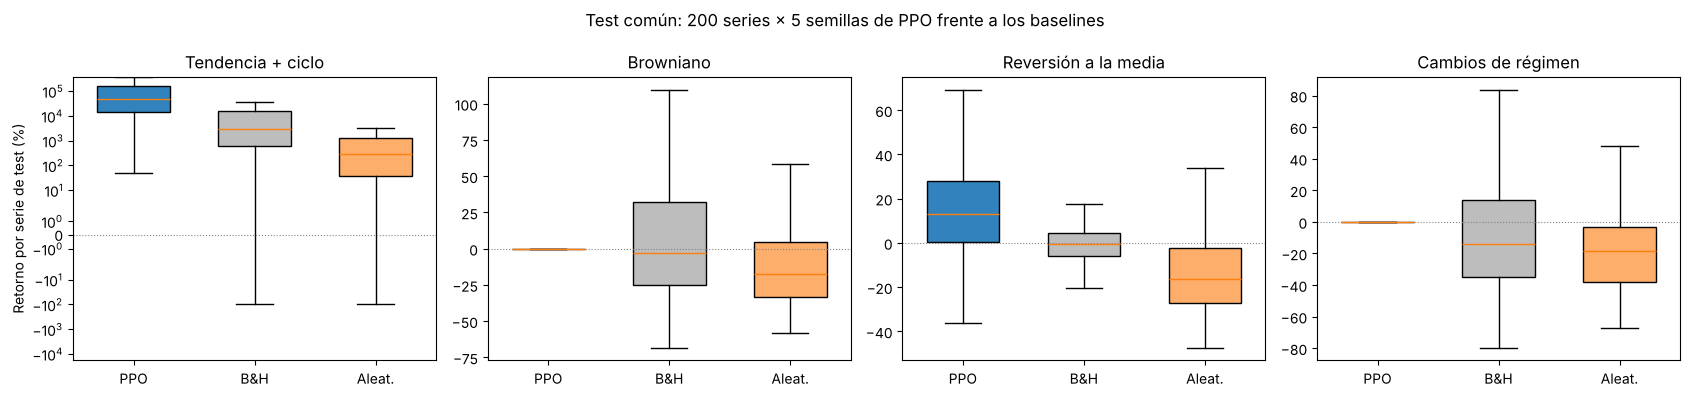

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (market, res) in zip(axes, RESULTS.items()):
    ppo = np.concatenate([e["returns"] for e in res["test"]]) * 100
    bh = res["baselines"]["buy_and_hold"]["returns"] * 100
    rnd = res["baselines"]["random"]["returns"] * 100
    bp = ax.boxplot([ppo, bh, rnd], showfliers=False, patch_artist=True, widths=0.6)
    for patch, c in zip(bp["boxes"], ["#3182bd", "#bdbdbd", "#fdae6b"]):
        patch.set_facecolor(c)
    ax.set_xticks([1, 2, 3], ["PPO", "B&H", "Aleat."]); ax.axhline(0, color="grey", lw=0.8, ls=":")
    ax.set_title(MARKET_LABELS[market])
    if market == "tendencia_ciclo": ax.set_yscale("symlog")
axes[0].set_ylabel("Retorno por serie de test (%)")
fig.suptitle("Test común: 200 series × 5 semillas de PPO frente a los baselines")
plt.tight_layout(); plt.show()

### Curvas de entrenamiento y convergencia (criterio heurístico común)

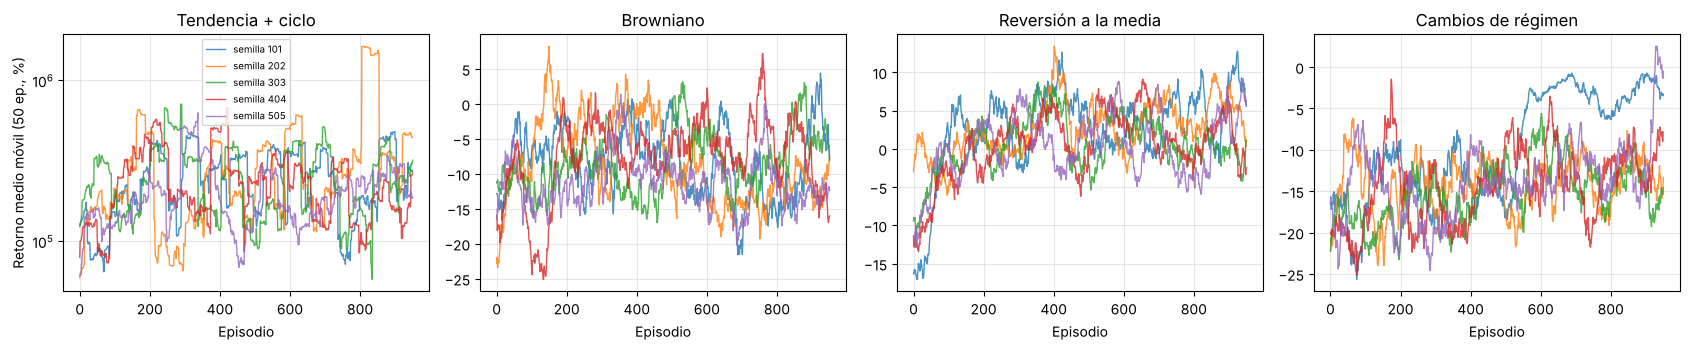

Mercado,Semillas estables,Episodio medio,Train/semilla (s)
Tendencia + ciclo,0/5,no detectada,39.5
Browniano,0/5,no detectada,41.9
Reversión a la media,0/5,no detectada,43.2
Cambios de régimen,0/5,no detectada,41.2


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
conv_rows = []
for ax, (market, res) in zip(axes, RESULTS.items()):
    conv = []
    for run in res["selected"]["runs"]:
        r = np.array([h["return"] for h in run["history"]])
        ax.plot(np.convolve(r, np.ones(50) / 50, mode="valid") * 100, lw=1, alpha=0.8, label=f"semilla {run['training_seed']}")
        conv.append(estimate_convergence_episode(r))
    ax.set_title(MARKET_LABELS[market]); ax.set_xlabel("Episodio"); ax.grid(alpha=.3)
    if market == "tendencia_ciclo": ax.set_yscale("symlog")
    stable = [c for c in conv if c is not None]
    conv_rows.append({"Mercado": MARKET_LABELS[market], "Semillas estables": f"{len(stable)}/5",
                      "Episodio medio": int(np.mean(stable)) if stable else None,
                      "Train/semilla (s)": np.mean([r["training_seconds"] for r in res["selected"]["runs"]])})
axes[0].set_ylabel("Retorno medio móvil (50 ep., %)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame(conv_rows).style.format(precision=1, na_rep="no detectada").hide(axis="index"))

## 7. Más allá del mínimo: PPO con estado enriquecido

Se reutiliza la configuración elegida para cada mercado (**sin reajustar**) cambiando solo el estado: se añade la distancia del precio a su
media móvil de 20 pasos (tabla de entrada 3-32-32). Como las 200 series de test son las mismas, la comparación es **por pares**
(media de las 5 semillas por serie, test de Wilcoxon).

In [17]:
RESULTS_ENR = {}
for market in PRICE_GENERATORS:
    path = Path("artifacts/ppo_enriquecido") / f"{market}.pt"
    if path.exists():
        RESULTS_ENR[market] = torch.load(path, weights_only=False)
    elif RUN_SEARCH:
        RESULTS_ENR[market] = run_market(market, "enriquecido", [PPOConfig(**{**RESULTS[market]["selected"]["config"], "state": "enriquecido"})])
rows = []
for market in RESULTS_ENR:
    o, e = RESULTS[market], RESULTS_ENR[market]
    po = np.stack([x["returns"] for x in o["test"]]).mean(0); pe = np.stack([x["returns"] for x in e["test"]]).mean(0)
    bh = o["baselines"]["buy_and_hold"]["returns"]
    d = pe - po
    p = 1.0 if np.all(d == 0) else wilcoxon(pe, po, zero_method="zsplit").pvalue
    rows.append({"Mercado": MARKET_LABELS[market], "PPO original (%)": 100 * o["test_summary"]["mean_return"],
                 "PPO enriquecido (%)": 100 * e["test_summary"]["mean_return"], "Mediana orig. (%)": 100 * o["test_summary"]["median_return"],
                 "Mediana enr. (%)": 100 * e["test_summary"]["median_return"], "P05 enr. (%)": 100 * e["test_summary"]["return_percentile_05"],
                 "Ops. enr.": e["test_summary"]["mean_trade_count"], "Enr. gana (% series)": 100 * np.mean(d > 0),
                 "p Wilcoxon": p, "Enr. > B&H (% series)": 100 * np.mean(pe > bh)})
enr_df = pd.DataFrame(rows)
num_cols = [c for c in enr_df.columns if c not in ("Mercado", "p Wilcoxon")]
display(enr_df.style.format("{:.2f}", subset=num_cols).format("{:.2g}", subset=["p Wilcoxon"]).hide(axis="index"))

Mercado,PPO original (%),PPO enriquecido (%),Mediana orig. (%),Mediana enr. (%),P05 enr. (%),Ops. enr.,Enr. gana (% series),p Wilcoxon,Enr. > B&H (% series)
Tendencia + ciclo,573038.08,438519.70,48052.66,71454.10,6221.13,54.03,77.50,3.9e-12,98.00
Browniano,1.54,5.40,0.00,-0.01,-49.43,1.12,47.00,0.59,45.50
Reversión a la media,15.92,41.56,12.86,38.13,-0.10,27.64,85.50,4.2e-28,97.50
Cambios de régimen,0.00,-1.77,0.00,0.00,-35.61,0.23,37.50,0.00013,62.00


## 8. Conclusiones

**1. PPO es competitivo con DQN y A3C bajo el mismo protocolo.** Sobre las mismas 200 series de test, con la misma red, el mismo presupuesto
(1.000 episodios × 5 semillas) y una rejilla más pequeña (16 configuraciones frente a 24): en **tendencia** PPO obtiene la mayor media y el mejor
P05 de los tres (573.038 % / 2.851 % frente a ≈ 247.000 % / ≈ 1.700-1.900 %), con 42 operaciones por serie; en **reversión** queda entre DQN
y A3C en retorno (15,9 % frente a 19,0 % y 11,1 %) con una cola intermedia (P05 −14,4 % frente a −16,8 % y −6,6 %) y menos operaciones que
DQN (34 frente a 43); en **browniano** y **regímenes** la política `argmax` de cuatro de cinco semillas se queda en efectivo, como DQN y A3C
(PPO 1,5 % y 0 %; la media positiva en browniano viene de una sola semilla que opera). Las cifras de tendencia son sintéticas y no extrapolables.

**2. La decisión de diseño que marca la diferencia es la escala de la observación, no el algoritmo.** Con la observación cruda del enunciado,
PPO degenera en acciones constantes en los cuatro mercados: el gradiente respecto a la tendencia (±0,02) es ~40 veces menor que respecto a la
posición (0/1), el objetivo recortado y la entropía decreciente fijan la acción constante antes de que la red llegue a usar la tendencia. DQN
lo sufre menos porque ε-greedy fuerza exploración durante 150-300 k transiciones. Estandarizar cada entrada con la desviación típica de 10 series
de entrenamiento (una práctica estándar en PPO) convierte el 0-2 % de validación en 11-20 % en reversión. Esto sugiere que parte de la diferencia
DQN-A3C del informe puede deberse también a la sensibilidad de cada algoritmo a la escala de entrada, no solo a su mecanismo de aprendizaje.

**3. El estado enriquecido vuelve a pesar más que el algoritmo (como en la parte 1).** Con la configuración elegida para el estado original y sin
reajustar nada, añadir la distancia del precio a su media de 20 pasos eleva reversión de 15,9 % a **41,6 %** (mediana 38 %, P05 −0,1 %, desviación
entre semillas 1,9 %, gana en el 86 % de las series, p ≈ 10⁻²⁸, supera a buy & hold en el 98 %), por encima de los tres algoritmos con estado
original (DQN 19 %) y del PPO tabular de la parte 1 (26 %). En tendencia gana en el 78 % de las series y mejora mediana y P05 (71.454 % y
6.221 %), aunque la media baja por valores extremos. En browniano no cambia nada (p = 0,59) y en regímenes empeora ligeramente (−1,8 %): una
semilla opera sobre ruido; una media de 20 pasos sigue siendo corta para fases de ≈ 50.

**4. Convergencia y coste.** Con el criterio heurístico común (bloques de 50 episodios, cambios relativos ≤ 5 %) ningún mercado se estabiliza,
igual que DQN y A3C. Las curvas de entrenamiento muestran además que el retorno *durante* el entrenamiento (política estocástica con entropía
0,05) es negativo en browniano y regímenes (≈ −10 %) mientras la política `argmax` queda en efectivo: PPO «sabe» que no conviene operar, pero el
bono de entropía le obliga a seguir probando. El tiempo de entrenamiento (≈ 40 s por modelo con 16 actores vectorizados) no es comparable con
los 48-98 s de DQN/A3C por tratarse de máquinas distintas.

**5. Límites.** Rejilla de 16 configuraciones (menor que la de DQN/A3C); el estado enriquecido no se reajustó; 5 semillas; mercados sintéticos;
las huellas SHA-256 del banco de test solo se reproducen en macOS/ARM (diferencias de redondeo ≤ 4·10⁻¹⁵ en otras plataformas, verificadas por
la igualdad exacta de los baselines con el informe), lo que aconseja versionar los bancos como ficheros. Siguientes pasos: reajustar
hiperparámetros con el estado enriquecido, probar ventanas más largas para regímenes y una evaluación confirmatoria común de los tres algoritmos
sobre un banco nuevo (semillas 30.000/40.000 reservadas por Javi).